# Generátory pseudonáhodných čísel

*Nad rámec cvičení — kapitola 4 skripta.*

---

Všechny ostatní sešity volají `random.random()` a věří mu. Tenhle sešit se ptá, **co se za tím voláním děje** a proč tomu věřit můžeme — zatímco generátoru, který roky používal celý svět, věřit nešlo.

- co je pseudonáhodná posloupnost a proč je to protimluv
- **lineární kongruenční generátor** (LCG): nejjednodušší, co funguje
- **mřížková struktura**: proč LCG nikdy nedá doopravdy nezávislé body
- **RANDU**: slavný generátor z IBM, jehož trojice leží na 15 rovinách
- **Mersenne Twister**: co používá Python a proč je jiný

Testování kvality (χ², frekvenční test, pokerový test a spol.) má vlastní sešit, `ch04_testy_generatoru`.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def perioda(krok, seed, limit=10_000_000):
    """Délka periody: kdy se stav poprvé zopakuje. Vrací None, když limit nestačí."""
    videno = {}
    x, i = seed, 0
    while i < limit:
        if x in videno:
            return i - videno[x]
        videno[x] = i
        x = krok(x)
        i += 1
    return None

## 1. Pseudonáhodná posloupnost

„Náhodná čísla z počítače" je protimluv. Počítač je deterministický stroj: ze stejného výchozího stavu vyrobí vždy stejnou posloupnost. Co tedy chceme?

Posloupnost, která je **deterministická**, ale **chová se jako nezávislá rovnoměrná čísla** ve všech ohledech, na kterých nám záleží. To je celá definice — a je nutně relativní: „ve všech ohledech, na kterých nám záleží".

Praktické důsledky:

- **Stav a semínko.** Generátor má vnitřní stav; semínko ho nastaví. Stejné semínko ⟹ stejná čísla. To není vada, to je **důvod**, proč jsou sešity reprodukovatelné.
- **Perioda.** Stav je konečný, takže se posloupnost nutně zacyklí. Perioda musí být mnohem větší než kolik čísel spotřebujeme.
- **Struktura.** Perioda je nutná podmínka, ne postačující. Posloupnost může mít obrovskou periodu a přitom skrytou závislost — a přesně na tom padl RANDU.

## 2. Lineární kongruenční generátor

Nejstarší použitelná konstrukce (Lehmer, 1949):

$$x_{n+1} = (a\,x_n + c) \bmod m, \qquad \gamma_n = \frac{x_n}{m}.$$

Tři parametry: násobitel $a$, přírůstek $c$, modul $m$. Maximální možná perioda je $m$ a dosáhne se jen při správné volbě (Hullova–Dobellova věta: $c$ nesoudělné s $m$; $a-1$ dělitelné každým prvočíselným dělitelem $m$; a je-li $m$ dělitelné 4, musí být i $a-1$).

Podívejme se, jak citlivá ta volba je.

In [2]:
def lcg(a, c, m, seed=1):
    """Lineární kongruenční generátor: vrací funkci, která dává další γ v [0, 1)."""
    stav = seed

    def dalsi():
        nonlocal stav
        stav = (a * stav + c) % m
        return stav / m

    return dalsi


print(f"{'a':>6} {'c':>5} {'m':>5}   {'perioda':>8}   {'z maxima':>9}")
for a, c, m in ((137, 187, 256), (136, 187, 256), (125, 0, 256), (5, 1, 256), (17, 3, 256)):
    p = perioda(lambda x: (a * x + c) % m, 1)
    print(f"{a:>6} {c:>5} {m:>5}   {p:>8}   {p / m:>8.0%}")

     a     c     m    perioda    z maxima
   137   187   256        256       100%
   136   187   256          1         0%
   125     0   256         64        25%
     5     1   256        256       100%
    17     3   256        256       100%


Stejný modul, podobně vypadající parametry — a perioda se liší od plné délky po pár kroků. Nic na generátoru zvenku nenapoví, který z nich je který; musí se to spočítat.

Jenže perioda je jen začátek.

## 3. Mřížka: co LCG nikdy neumí

Vezměme dvojice po sobě jdoucích čísel $(\gamma_n, \gamma_{n+1})$ a nakresleme je jako body ve čtverci. Kdyby čísla byla nezávislá, dostaneme rovnoměrně posetý čtverec.

Nedostaneme. Z definice je $x_{n+1} = a x_n + c - m\lfloor\cdot\rfloor$, což je **lineární** vztah — a všechny body padnou na soustavu rovnoběžných přímek. To je Marsagliova věta (1968): dvojice z LCG leží v rovině na nejvýše $\sqrt{2m}$ přímkách, trojice v prostoru na nejvýše $(6m)^{1/3}$ rovinách.

Mřížka je nevyhnutelná. Otázkou je jen, jestli je dost jemná na to, aby nám nevadila.

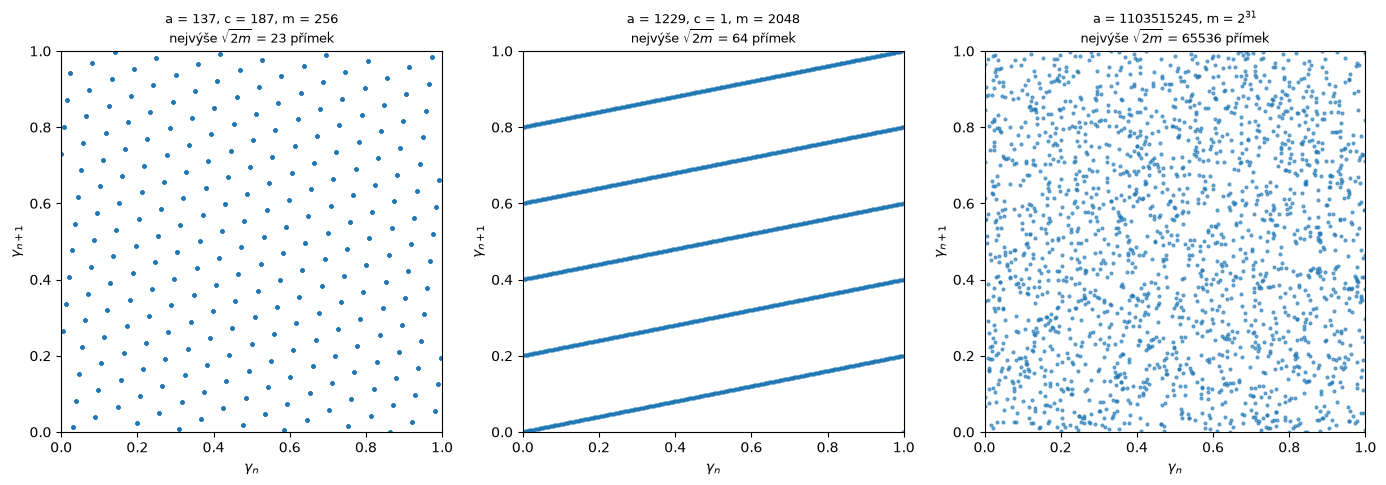

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
M_ = 2048

for ax, (a, c, m, nazev) in zip(axes, (
        (137, 187, 256, "a = 137, c = 187, m = 256"),
        (1229, 1, 2048, "a = 1229, c = 1, m = 2048"),
        (1103515245, 12345, 2**31, "a = 1103515245, m = $2^{31}$"))):
    gen = lcg(a, c, m)
    xs = [gen() for _ in range(M_)]
    ax.scatter(xs[:-1], xs[1:], s=4, alpha=0.6)
    ax.set_xlabel(r"$\gamma_n$")
    ax.set_ylabel(r"$\gamma_{n+1}$")
    ax.set_title(f"{nazev}\nnejvýše $\\sqrt{{2m}}$ = {math.sqrt(2 * m):.0f} přímek", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

Vlevo je mřížka do očí bijící: 256 možných stavů znamená 256 bodů a pár přímek. Uprostřed je jemnější. Vpravo, s modulem $2^{31}$, už ji na obrázku nerozeznáme — přímek je nejvýše 65 536 a mezery mezi nimi jsou pod rozlišením obrázku.

**Pozor na závěr.** Vpravo mřížka nezmizela, jen ji nevidíme. A právě tahle neviditelnost dělá z další ukázky klasiku.

## 4. RANDU: jak to dopadne, když se mřížka netrefí

RANDU je generátor dodávaný IBM v 60. a 70. letech a použitý v tisících vědeckých prací:

$$x_{n+1} = 65539\,x_n \bmod 2^{31}.$$

Perioda je $2^{29}$, dvojice vypadají v pořádku. Jenže $65539 = 2^{16} + 3$, a z toho plyne

$$x_{n+2} = 6x_{n+1} - 9x_n \pmod{2^{31}},$$

tedy přesná lineární závislost **tří** po sobě jdoucích čísel. Ověříme ji a pak se podíváme, co dělá s trojicemi v prostoru.

In [4]:
A_RANDU, M_RANDU = 65539, 2**31

x = 1
stavy = []
for _ in range(100_000):
    x = (A_RANDU * x) % M_RANDU
    stavy.append(x)

zbytky = {(9 * stavy[i] - 6 * stavy[i + 1] + stavy[i + 2]) % M_RANDU for i in range(len(stavy) - 2)}
print(f"hodnot (9 x_n - 6 x_(n+1) + x_(n+2)) mod 2^31: {len(zbytky)}  ->  {zbytky}")

us = [s / M_RANDU for s in stavy]
roviny = sorted({round(9 * us[i] - 6 * us[i + 1] + us[i + 2]) for i in range(len(us) - 2)})
print(f"v jednotkách γ tedy 9γ_n - 6γ_(n+1) + γ_(n+2) = k pro celé k: {roviny}")
print(f"počet rovin: {len(roviny)}")

hodnot (9 x_n - 6 x_(n+1) + x_(n+2)) mod 2^31: 1  ->  {0}
v jednotkách γ tedy 9γ_n - 6γ_(n+1) + γ_(n+2) = k pro celé k: [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
počet rovin: 15


Je to přesná rovnost, ne přibližná: **každá** trojice po sobě jdoucích čísel z RANDU leží na jedné z patnácti rovin $9\gamma_n - 6\gamma_{n+1} + \gamma_{n+2} = k$, $k = -5,\dots,9$.

Dvourozměrné obrázky to neodhalí — závislost je trojrozměrná. Proto se na RANDU přišlo až po letech používání.

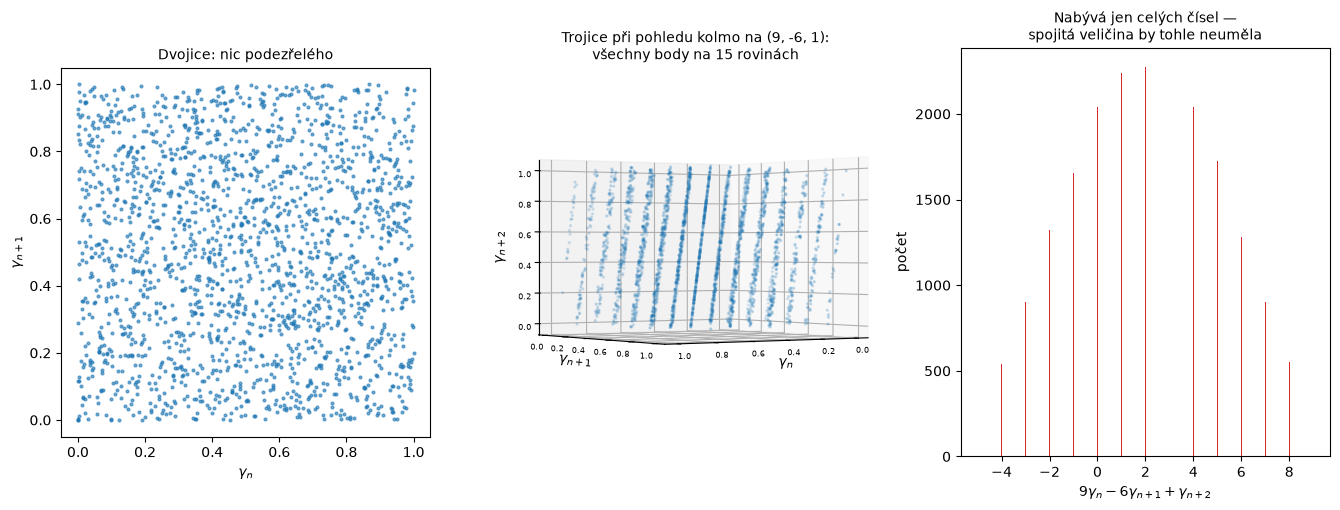

In [5]:
fig = plt.figure(figsize=(13.5, 5.2))

# vlevo: dvojice vypadají bezvadně
ax = fig.add_subplot(1, 3, 1)
ax.scatter(us[:2000], us[1:2001], s=4, alpha=0.6)
ax.set_xlabel(r"$\gamma_n$"); ax.set_ylabel(r"$\gamma_{n+1}$")
ax.set_title("Dvojice: nic podezřelého", fontsize=10)
ax.set_aspect("equal")

# uprostřed: trojice v prostoru, natočené tak, aby byly roviny vidět z boku
ax = fig.add_subplot(1, 3, 2, projection="3d")
n3 = 3000
ax.scatter(us[:n3], us[1:n3 + 1], us[2:n3 + 2], s=2, alpha=0.5)
ax.view_init(elev=0, azim=56.31)   # pohled kolmo na normálu (9, -6, 1): roviny se ukážou z boku
ax.set_xlabel(r"$\gamma_n$", labelpad=-6); ax.set_ylabel(r"$\gamma_{n+1}$", labelpad=-6)
ax.set_zlabel(r"$\gamma_{n+2}$", labelpad=-4)
ax.tick_params(labelsize=6, pad=-2)
ax.set_title("Trojice při pohledu kolmo na (9, -6, 1):\nvšechny body na 15 rovinách", fontsize=10)

# vpravo: totéž jako histogram kombinace, která je celočíselná
ax = fig.add_subplot(1, 3, 3)
kombinace = [9 * us[i] - 6 * us[i + 1] + us[i + 2] for i in range(20_000)]
ax.hist(kombinace, bins=600, color="tab:red")
ax.set_xlabel(r"$9\gamma_n - 6\gamma_{n+1} + \gamma_{n+2}$")
ax.set_ylabel("počet")
ax.set_title("Nabývá jen celých čísel —\nspojitá veličina by tohle neuměla", fontsize=10)

plt.tight_layout()
plt.show()

Prostřední obrázek je ten slavný: z běžného úhlu vypadá krychle poctivě poseta body, ale natočená ukáže, že je prázdná a všechno sedí na pár rovinách. Pravý obrázek říká totéž bez 3D: spojitá náhodná veličina by nikdy nenabývala jen celých hodnot.

**Poučení není „RANDU byl špatný".** Poučení je, že mřížkovou strukturu *mají všechny LCG*, jen v různé jemnosti, a že se projeví až v dimenzi, ve které ji zrovna testujete. Simulace běžící v šesti rozměrech může narazit na strukturu, kterou dvourozměrný obrázek nikdy neukáže.

## 5. Mersenne Twister: co používá Python

`random.random()` v Pythonu je Mersenne Twister MT19937 (Matsumoto a Nišimura, 1998). Je postavený jinak než LCG — pracuje se stavem o 19 937 bitech, který míchá posuvy a operacemi XOR (lineární posuvný registr nad $\mathbb{F}_2$), ne násobením modulo.

Co z toho plyne:

- **Perioda $2^{19937} - 1$.** Pro srovnání, počet atomů ve vesmíru je kolem $2^{266}$.
- **Rovnoměrnost do 623 rozměrů.** Trojice z RANDU ležely na 15 rovinách; u MT19937 je zaručeno, že i 623-tice pokrývají prostor rovnoměrně.
- **Není kryptograficky bezpečný.** Z 624 po sobě jdoucích výstupů se dá zrekonstruovat celý stav a dopočítat budoucnost. Na simulace to nevadí, na hesla nebo klíče ano — tam patří `secrets`.

Stejný test, jaký položil RANDU, pustíme na Pythonův generátor.

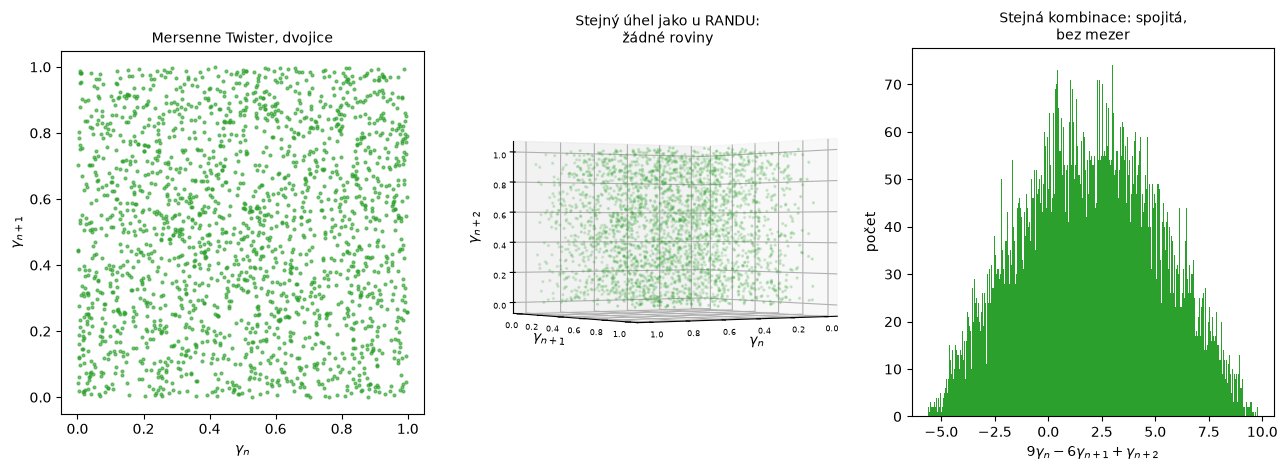

perioda MT19937 = 2^19937 - 1 ≈ 10^6002
velikost stavu: 2.43 kB


In [6]:
n3 = 3000
mt = [random.random() for _ in range(n3 + 2)]

fig = plt.figure(figsize=(13, 4.8))

ax = fig.add_subplot(1, 3, 1)
ax.scatter(mt[:2000], mt[1:2001], s=4, alpha=0.6, color="tab:green")
ax.set_xlabel(r"$\gamma_n$"); ax.set_ylabel(r"$\gamma_{n+1}$")
ax.set_title("Mersenne Twister, dvojice", fontsize=10)
ax.set_aspect("equal")

ax = fig.add_subplot(1, 3, 2, projection="3d")
ax.scatter(mt[:n3], mt[1:n3 + 1], mt[2:n3 + 2], s=2, alpha=0.5, color="tab:green")
ax.view_init(elev=0, azim=56.31)   # úplně stejný pohled jako u RANDU
ax.set_xlabel(r"$\gamma_n$", labelpad=-6); ax.set_ylabel(r"$\gamma_{n+1}$", labelpad=-6)
ax.set_zlabel(r"$\gamma_{n+2}$", labelpad=-4)
ax.tick_params(labelsize=6, pad=-2)
ax.set_title("Stejný úhel jako u RANDU:\nžádné roviny", fontsize=10)

ax = fig.add_subplot(1, 3, 3)
mt2 = [random.random() for _ in range(20_002)]
ax.hist([9 * mt2[i] - 6 * mt2[i + 1] + mt2[i + 2] for i in range(20_000)], bins=600, color="tab:green")
ax.set_xlabel(r"$9\gamma_n - 6\gamma_{n+1} + \gamma_{n+2}$")
ax.set_ylabel("počet")
ax.set_title("Stejná kombinace: spojitá,\nbez mezer", fontsize=10)

plt.tight_layout()
plt.show()

print(f"perioda MT19937 = 2^19937 - 1 ≈ 10^{19937 * math.log10(2):.0f}")
print(f"velikost stavu: {19937 / 8 / 1024:.2f} kB")

## 6. Praktická pravidla

1. **Nepište si vlastní generátor.** Tenhle sešit ukazuje proč: i parametry, které prošly recenzí a dostaly se do produktu IBM, byly vadné způsobem, který se neprojevil roky.
2. **Semínko nastavte a zapište.** `random.seed(1)` na začátku sešitu je to, co dělá výsledky reprodukovatelnými.
3. **Nemíchejte simulaci a bezpečnost.** Na simulace `random`, na cokoliv tajného `secrets`.
4. **Paralelní běhy potřebují péči.** Dva procesy se stejným semínkem spočítají totéž. V NumPy na to slouží `default_rng(seed).spawn(k)`.
5. **Nepoužívejte `random.random()` pro velká pole.** Pro vektorové výpočty je `numpy.random.default_rng()` řádově rychlejší (a MT nahradilo PCG64).

## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| Pseudonáhodnost | determinismus, který se chová jako náhoda ve všech sledovaných ohledech |
| LCG | $x_{n+1} = (a x_n + c)\bmod m$; perioda závisí citlivě na $a, c, m$ |
| Marsagliova věta | $d$-tice z LCG leží na nejvýše $(d!\,m)^{1/d}$ nadrovinách — mřížka je nevyhnutelná |
| RANDU | $9\gamma_n - 6\gamma_{n+1} + \gamma_{n+2}$ je celé číslo ⟹ trojice na 15 rovinách |
| Mersenne Twister | perioda $2^{19937}-1$, rovnoměrnost do 623 rozměrů, **ne** kryptograficky bezpečný |
| Hlavní poučení | dobrá perioda nestačí; závislost se může schovávat v dimenzi, kterou netestujete |

### Zkuste si

1. Najděte parametry LCG s $m = 2^{16}$, které podle Hullovy–Dobellovy věty dávají plnou periodu, a ověřte to funkcí `perioda`.
2. Nakreslete mřížku dvojic pro $m = 1024$ a několik různých $a$. Které $a$ dává nejhorší (nejhrubší) mřížku a proč?
3. Spočítejte, kolik rovin Marsagliova mez připouští pro trojice z RANDU, a porovnejte s naměřenými patnácti.
4. Odhadněte $\pi$ metodou trefa/netrefa pomocí RANDU místo `random.random()`. Kolik bodů je potřeba, než se chyba začne chovat jinak než $1/\sqrt{N}$?
5. Vezměte LCG s malým modulem ($m = 2^{10}$) a spočítejte jím integrál $\int_0^1 e^{-x^2}dx$. Srovnejte chybu s `random.random()` při stejném $N$. Kde se projeví perioda?